In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [18]:
df_original = pd.read_csv('../data/processed/dataframe_classificado.csv')
df_original

,CONTA,FINANCEIRO,QUANTIDADE,NOME ATIVO,TIPO DE ATIVO,PERFIL DA CARTEIRA,CLASSIFICACAO DO ATIVO
0,27,1.627826e+04,16.0,CRI CDIE,TITULOS RF PRIVADOS BRASIL,Moderado,Renda Fixa
1,27,2.508162e+04,25.0,CRA CDIE,TITULOS RF PRIVADOS BRASIL,Moderado,Renda Fixa
2,27,4.704625e+04,49.0,CRA IPCA,TITULOS RF PRIVADOS BRASIL,Moderado,Renda Fixa
3,27,3.633148e+04,35.0,RRRP13 IPCA,DEBENTURES BRASIL,Moderado,Renda Fixa
4,27,1.899562e+04,20.0,EEELA1 IPCA,DEBENTURES BRASIL,Moderado,Renda Fixa
...,...,...,...,...,...,...,...
286141,6178808,3.890751e+05,400.0,RSAN16 IPCA,DEBENTURES BRASIL,Sofisticado,Renda Fixa
286142,6178808,4.049765e+05,423.0,CMGDB1 IPCA,DEBENTURES BRASIL,Sofisticado,Renda Fixa
286143,6178808,1.576249e+06,1557.0,EGIEB4 IPCA,DEBENTURES BRASIL,Sofisticado,Renda Fixa
286144,6184909,5.002625e+05,637.0,NTNF PRE,TITULOS RF PUBLICOS BRASIL,Conservador,Renda Fixa


In [19]:
df_contas_perfil = df_original[['CONTA', 'PERFIL DA CARTEIRA']].drop_duplicates()
df_contas_perfil

,CONTA,PERFIL DA CARTEIRA
0,27,Moderado
70,44,Sofisticado
193,103,Moderado
343,285,Conservador
453,299,Conservador
...,...,...
286068,6150189,Conservador
286070,6167502,Conservador
286115,6178808,Sofisticado
286144,6184909,Conservador


In [20]:
distribuicao = pd.read_csv('../data/processed/percentual_de_distribuicao.csv')

In [21]:
distribuicao

,Conta,Renda Fixa,Renda Variável
0,27,100.0,0.0
1,44,100.0,0.0
2,103,100.0,0.0
3,285,100.0,0.0
4,299,100.0,0.0
...,...,...,...
6096,6150189,0.0,100.0
6097,6167502,100.0,0.0
6098,6178808,100.0,0.0
6099,6184909,100.0,0.0


In [22]:
distribuicao['PERFIL ENCONTRADO'] = np.select(
    [
        # Conservador: 90%+ em Renda Fixa
        (distribuicao['Renda Fixa'] >= 90.0),
        # Sofisticado/Arrojado: 70%+ em Renda Variável
        (distribuicao['Renda Variável'] >= 70.0)
    ],
    [
        'Conservador',
        'Sofisticado'
    ],
    default='Moderado'
)
distribuicao

,Conta,Renda Fixa,Renda Variável,PERFIL ENCONTRADO
0,27,100.0,0.0,Conservador
1,44,100.0,0.0,Conservador
2,103,100.0,0.0,Conservador
3,285,100.0,0.0,Conservador
4,299,100.0,0.0,Conservador
...,...,...,...,...
6096,6150189,0.0,100.0,Sofisticado
6097,6167502,100.0,0.0,Conservador
6098,6178808,100.0,0.0,Conservador
6099,6184909,100.0,0.0,Conservador


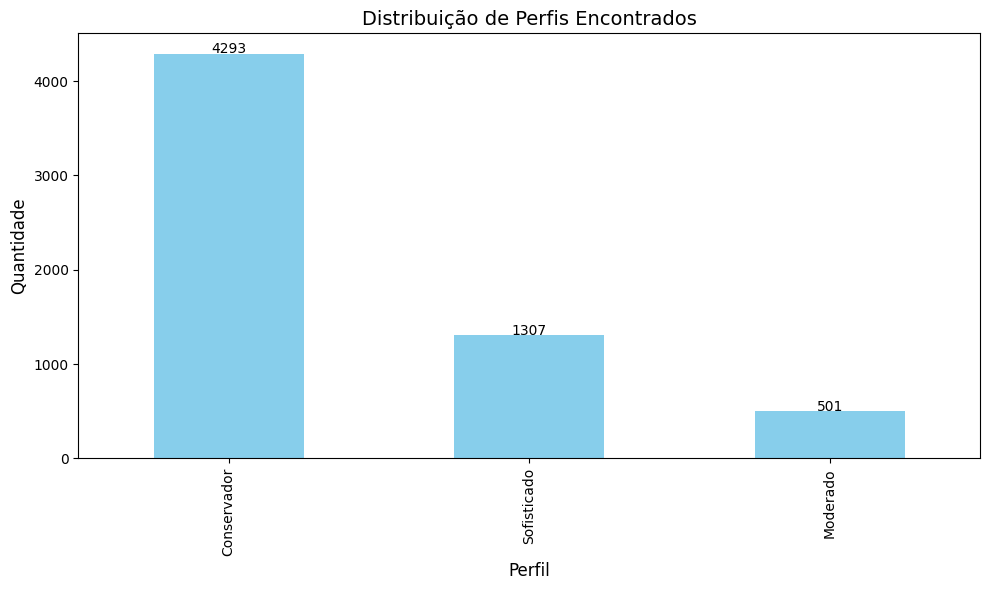

In [23]:
perfil_count = distribuicao['PERFIL ENCONTRADO'].value_counts()

plot = perfil_count.plot(kind='bar', figsize=(10, 6), color='skyblue')
plot.set_title('Distribuição de Perfis Encontrados', fontsize=14)
plot.set_xlabel('Perfil', fontsize=12)
plot.set_ylabel('Quantidade', fontsize=12)

for i, v in enumerate(perfil_count):
    plot.text(i, v + 5, str(v), ha='center')

plt.tight_layout()
plt.show()

In [25]:
distribuicao.to_csv('../data/processed/classificacao_encontrada_por_carteira.csv', index=False)